# Explainable AI and feature analysis

## How to Run This Notebook

This notebook explains the calibrated SVM model trained by Member 1 using SHAP (SHapley Additive exPlanations) and a surrogate decision tree.

### 1. Prerequisites

- Python 3.12
- Visual Studio Code with Python and Jupyter extensions
- Project Python environment (`Python (PPD Project)`)
- scikit-learn 1.8.0
- Required libraries: `numpy`, `pandas`, `matplotlib`, `shap`, `scikit-learn`

### 2. Project Setup

1. Download or clone the complete `PPD_ML_Prediction` project.
2. Open the project folder in VS Code.
3. Make sure the saved model, processed datasets, and `src` folder are available.
4. Open `notebooks/07_explainable_ai.ipynb`.

### 3. Select the Python Kernel

1. Click **Select Kernel** at the top-right of the notebook.
2. Select **Python (PPD Project)**.
3. Confirm that the environment uses scikit-learn version `1.8.0`.

If SHAP is not installed, run the following command in a notebook cell:

```python
%pip install shap==0.51.0
```

Restart the kernel after installation.

### 4. Run the Notebook

1. Open the notebook in VS Code.
2. Select the correct Python kernel.
3. Click **Run All** or execute the cells from top to bottom.
4. Wait for the SHAP calculations and plots to finish.
5. Check that the outputs appear without errors.

**Note:** The SHAP calculations may take some time depending on the computer.

### 5. Expected Outputs

The notebook generates:

- SHAP waterfall plot for an individual prediction
- Local prediction explanation in simple language
- SHAP feature importance summary
- SHAP stability comparison
- Surrogate decision tree visualization
- Surrogate model fidelity comparison

Generated files are saved in:

`outputs/member2_xai/`





## 1. Load the saved model and data

The training data gives SHAP its reference group. The test data supplies the records we explain. The project already provides helpers to convert questionnaire answers into a form SHAP can use.

In [12]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

project = Path.cwd()
if project.name == "notebooks":
    project = project.parent

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)
if sklearn.__version__ != "1.8.0":
    raise RuntimeError("Choose the PPD Project kernel with scikit-learn 1.8.0.")

sys.path.insert(0, str(project))
from src.predict import load_model, make_shap_predictor, to_shap_inputs

data_folder = project / "dataset" / "processed"
artifact = load_model()

# Keep the literal answer "none". Treat blank cells as missing.
options = {"index_col": "row_id", "keep_default_na": False, "na_values": [""]}
train = pd.read_csv(data_folder / "X_train_clean.csv", **options)
test = pd.read_csv(data_folder / "X_test_clean.csv", **options)

predict_high = make_shap_predictor(artifact, label="High")
print("Model:", artifact["model_name"])
print("Training and test rows:", len(train), len(test))
print("Questionnaire fields:", test.shape[1])

Python: c:\Users\jayan\ppd-venv\Scripts\python.exe
scikit-learn: 1.8.0
Model: SVM
Training and test rows: 640 160
Questionnaire fields: 21


## 2. Calculate SHAP values

Explain 10 test records using 20 randomly selected training records as a reference. The same seed selects the same records each time. Each contribution measures how a field moves the **High** probability relative to the reference.

We check that the reference probability plus all contributions equals the model's probability. This checks that the numbers add up.

In [13]:
import shap

test_sample = test.sample(n=10, random_state=42)
sample_inputs = to_shap_inputs(test_sample, artifact)

def explain_sample(background_seed):
    reference = train.sample(n=20, random_state=background_seed)
    background = to_shap_inputs(reference, artifact)
    masker = shap.maskers.Independent(background)
    explainer = shap.PermutationExplainer(predict_high, masker, seed=42)

    # Repeat the feature ordering experiment five times.
    evaluations = 5 * (2 * sample_inputs.shape[1] + 1)
    result = explainer(sample_inputs, max_evals=evaluations)

    reconstructed = result.base_values + result.values.sum(axis=1)
    np.testing.assert_allclose(reconstructed, predict_high(sample_inputs), atol=1e-8)
    return result

explanations = explain_sample(background_seed=42)
print("SHAP reconstruction passed for", len(test_sample), "test records.")

SHAP reconstruction passed for 10 test records.


## 3. Explain one record with a waterfall plot

The chart starts at the reference average. Red arrows increase the model's High probability and blue arrows decrease it. The field labels show the original responses, including any missing answer.

Reference average: 45.5%
Model's High probability: 50.5%


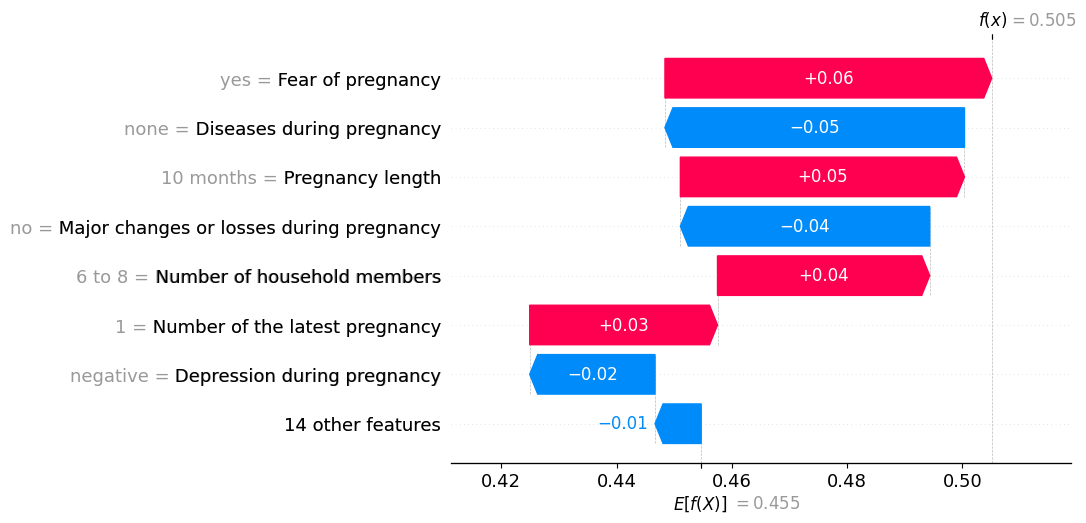

In [14]:
output_folder = project / "outputs" / "member2_xai"
output_folder.mkdir(parents=True, exist_ok=True)

explanations.display_data = test_sample.to_numpy()
local = explanations[0]
high_probability = float(predict_high(sample_inputs.iloc[:1])[0])

print(f"Reference average: {float(local.base_values):.1%}")
print(f"Model's High probability: {high_probability:.1%}")
shap.plots.waterfall(local, max_display=8, show=False)
plt.savefig(output_folder / "local_waterfall.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Explain the prediction in simple words

The strongest contributions are those farthest from zero. A contribution of 0.05 is **5 percentage points**. The directions describe this model's behavior for this record.

In [15]:
changes = pd.Series(local.values, index=test_sample.columns)
top_fields = changes.abs().nlargest(3).index

lines = [
    f"The model gave this record a {high_probability:.1%} probability of the High EPDS screening category.",
    f"The average High probability in the reference group was {float(local.base_values):.1%}."
]
for field in top_fields:
    change = changes[field] * 100
    if abs(change) < 0.05:
        lines.append(f"{field} made a contribution close to zero.")
    else:
        direction = "up" if change > 0 else "down"
        lines.append(f"{field} moved the model's High probability {direction} by {abs(change):.1f} percentage points.")

explanation_text = "\n".join(lines)
print(explanation_text)
(output_folder / "local_explanation.txt").write_text(explanation_text, encoding="utf-8")

The model gave this record a 50.5% probability of the High EPDS screening category.
The average High probability in the reference group was 45.5%.
Fear of pregnancy moved the model's High probability up by 5.7 percentage points.
Diseases during pregnancy moved the model's High probability down by 5.2 percentage points.
Pregnancy length moved the model's High probability up by 4.9 percentage points.


401

## 5. Summarize feature importance

Rank fields by the average size of their contributions across the 10 test records. The summary plot shows direction as well as size. Each dot represents one record's contribution for one field. We use one color because the category codes have no high-to-low ordering.

,Mean absolute contribution (percentage points)
Fear of pregnancy,6.00
Major changes or losses during pregnancy,5.06
Pregnancy plan,3.00
Diseases during pregnancy,2.94
Disease before pregnancy,2.72
Education Level,2.54
Occupation before latest pregnancy,2.51
Pregnancy length,2.46


C:\Users\jayan\AppData\Local\Temp\ipykernel_16064\3056253009.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


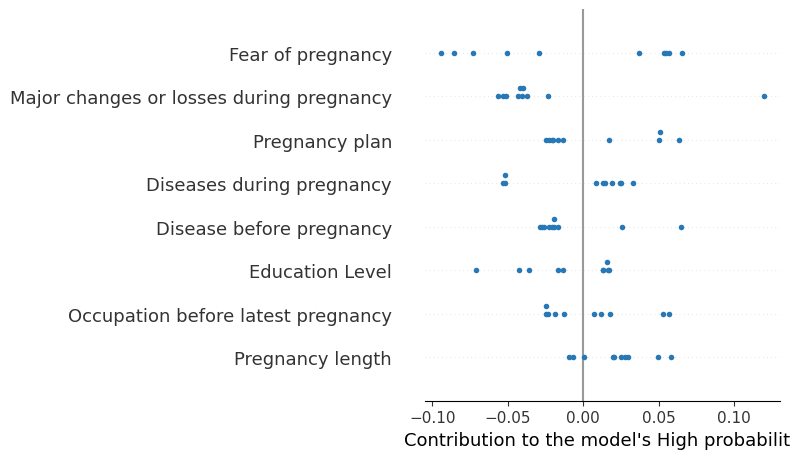

In [16]:
importance = pd.Series(
    np.abs(explanations.values).mean(axis=0) * 100,
    index=test_sample.columns,
    name="Mean absolute contribution (percentage points)"
).sort_values(ascending=False)

display(importance.head(8).round(2).to_frame())
importance.to_csv(output_folder / "global_importance.csv", index_label="feature")

shap.summary_plot(
    explanations.values, feature_names=test_sample.columns.tolist(),
    plot_type="dot", color="#2878B5", max_display=8, show=False
)
plt.xlabel("Contribution to the model's High probability")
plt.savefig(output_folder / "shap_summary.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Check whether the explanations change

Use a second training reference sample and keep the same 10 test records. Compare the three highest-ranked fields and the average change in contributions. This is a small check of how much the chosen background matters.

In [17]:
second_explanations = explain_sample(background_seed=99)
second_importance = pd.Series(
    np.abs(second_explanations.values).mean(axis=0),
    index=test_sample.columns
)

first_top = importance.head(3).index.tolist()
second_top = second_importance.nlargest(3).index.tolist()
overlap = len(set(first_top) & set(second_top))
mean_change = np.abs(explanations.values - second_explanations.values).mean()

display(pd.DataFrame({"First reference": first_top, "Second reference": second_top}))
print(f"Shared top fields: {overlap} out of 3")
print(f"Average change: {100 * mean_change:.2f} percentage points")

PermutationExplainer explainer: 11it [00:17,  3.41s/it]                        


,First reference,Second reference
0,Fear of pregnancy,Fear of pregnancy
1,Major changes or losses during pregnancy,Major changes or losses during pregnancy
2,Pregnancy plan,Pregnancy plan


Shared top fields: 3 out of 3
Average change: 0.70 percentage points


## 7. Train a small tree to imitate the SVM

The tree uses the project's encoded feature tables and learns the **SVM's High probabilities** on training records. This makes it a surrogate. We use row IDs to match the original and encoded records. The tree has at most three levels of splits so its rules are easy to inspect.

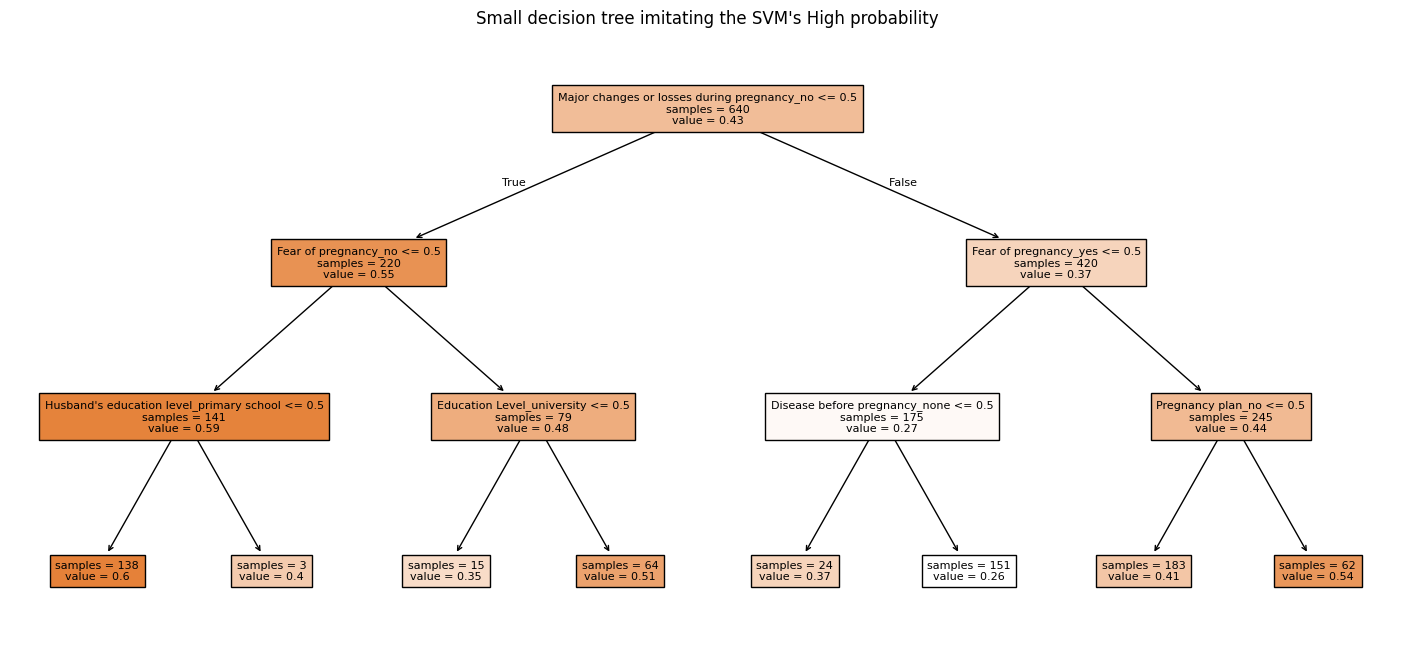

In [18]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

encoded_train = pd.read_csv(data_folder / "X_train.csv", index_col="row_id")
encoded_test = pd.read_csv(data_folder / "X_test.csv", index_col="row_id")

# Match the row order before fitting or comparing scores.
train_high = predict_high(to_shap_inputs(train.loc[encoded_train.index], artifact))
test_high = predict_high(to_shap_inputs(test.loc[encoded_test.index], artifact))

tree = DecisionTreeRegressor(max_depth=3, random_state=42)
tree.fit(encoded_train, train_high)
tree_high = tree.predict(encoded_test)

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=encoded_train.columns.tolist(),
          filled=True, impurity=False, precision=2, fontsize=8)
plt.title("Small decision tree imitating the SVM's High probability")
plt.savefig(output_folder / "surrogate_tree.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Compare the tree with the original model

**Fidelity** is how closely the tree imitates the SVM on test records. Compare the tree's average error with a simple reference that always predicts the mean SVM training score. Also inspect the record where the tree and SVM disagree the most.

In [19]:
from sklearn.metrics import mean_absolute_error

tree_error = mean_absolute_error(test_high, tree_high) * 100
constant_scores = np.full(len(test_high), train_high.mean())
constant_error = mean_absolute_error(test_high, constant_scores) * 100

print(f"Tree's average error: {tree_error:.2f} percentage points")
print(f"Constant reference error: {constant_error:.2f} percentage points")

comparison = pd.DataFrame({
    "SVM High (%)": test_high * 100,
    "Tree High (%)": tree_high * 100,
    "Absolute gap (percentage points)": np.abs(test_high - tree_high) * 100
}, index=encoded_test.index)

largest_gap = comparison.nlargest(1, "Absolute gap (percentage points)")
display(largest_gap.round(2))
comparison.to_csv(output_folder / "surrogate_comparison.csv")

Tree's average error: 8.52 percentage points
Constant reference error: 14.12 percentage points


,SVM High (%),Tree High (%),Absolute gap (percentage points)
row_id,,,
120,61.14,25.59,35.56
